<a href="https://colab.research.google.com/github/DeisyUdec/Proyecto-estad-sticas-de-Youtube/blob/main/sentimeintovideo_youtobe_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MODELO DE PLN PARA VIDEOS DE YOUTUBE
Dimensiones originales: (18409, 5)
Columnas: ['Unnamed: 0', 'Video ID', 'Comment', 'Likes', 'Sentiment']


,Unnamed: 0,Video ID,Comment,Likes,Sentiment
0,0,wAZZ-UWGVHI,Let's not forget that Apple Pay in 2014 requir...,95.0,1.0
1,1,wAZZ-UWGVHI,Here in NZ 50% of retailers don’t even have co...,19.0,0.0
2,2,wAZZ-UWGVHI,I will forever acknowledge this channel with t...,161.0,2.0
3,3,wAZZ-UWGVHI,Whenever I go to a place that doesn’t take App...,8.0,0.0
4,4,wAZZ-UWGVHI,"Apple Pay is so convenient, secure, and easy t...",34.0,2.0



2. Datos faltantes:
Video ID     0
Comment      0
Likes        0
Sentiment    0
dtype: int64

Cantidad de comentarios: 18409
Cantidad de videos: 1869

3. Estadistica descriptiva:


,Likes,Longitud_comentario,Sentiment
count,18409.000000,18409.000000,18409.000000
mean,1040.019447,185.916400,1.493998
std,10651.366148,268.444433,0.709928
min,0.000000,0.000000,0.000000
25%,5.000000,70.000000,1.000000
50%,29.000000,117.000000,2.000000
75%,190.000000,209.000000,2.000000
max,891372.000000,8945.000000,2.000000



Distribucion de sentimientos:
Sentiment
2.0    11432
1.0     4639
0.0     2338
Name: count, dtype: int64


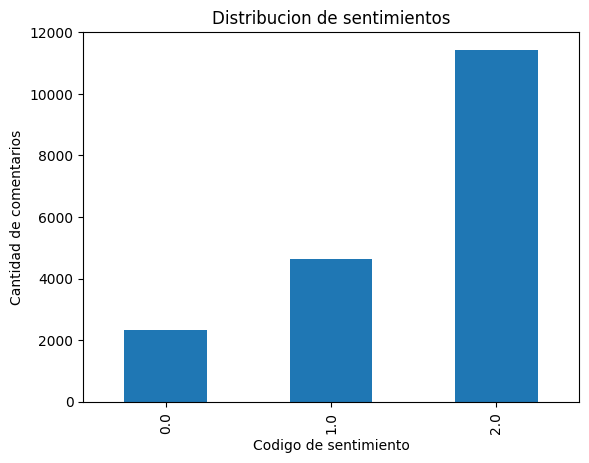


4. Palabras mas frecuentes:
[('your', 2978), ('like', 2644), ('just', 2597), ('can', 2512), ('all', 2472), ('they', 2456), ('how', 2253), ('love', 2170), ('what', 2073), ('one', 2047), ('video', 1962), ('more', 1912), ('when', 1816), ('from', 1777), ('about', 1770)]


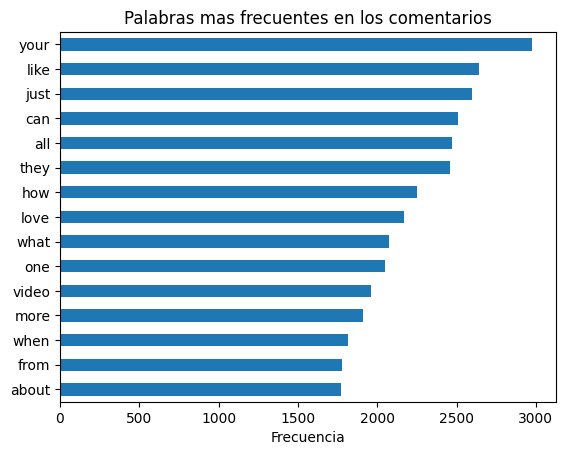


5. Videos preparados: 1869

Correlaciones entre variables numericas:


,Cantidad_comentarios,Sentimiento_promedio,Likes_comentarios
Cantidad_comentarios,1.000000,0.076992,0.048015
Sentimiento_promedio,0.076992,1.000000,0.005719
Likes_comentarios,0.048015,0.005719,1.000000



6. Distribucion de niveles de interaccion:
Desempeno
Bajo     623
Medio    623
Alto     623
Name: count, dtype: int64


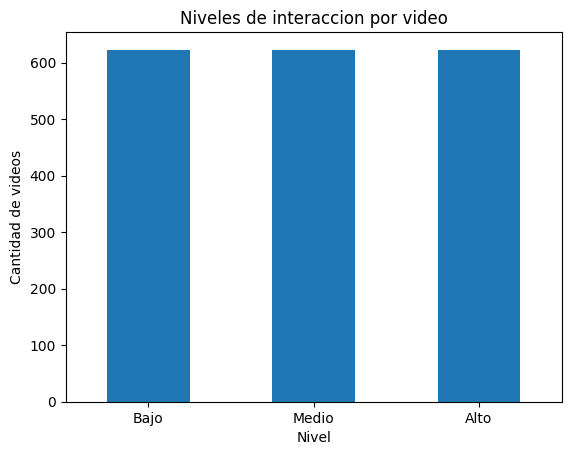


7. Videos para entrenar: 1495
Videos para probar: 374

8. Entrenamiento y evaluacion

9. Comparacion de modelos:


,Modelo,Exactitud,Precision_macro,Recall_macro,F1_macro
0,Regresion Logistica,0.596,0.604,0.596,0.598
1,Bosque Aleatorio,0.559,0.571,0.559,0.561



MODELO SELECCIONADO: Regresion Logistica

10. Reporte de clasificacion:
              precision    recall  f1-score   support

        Bajo       0.71      0.62      0.66       125
       Medio       0.50      0.53      0.51       125
        Alto       0.60      0.65      0.62       124

    accuracy                           0.60       374
   macro avg       0.60      0.60      0.60       374
weighted avg       0.60      0.60      0.60       374



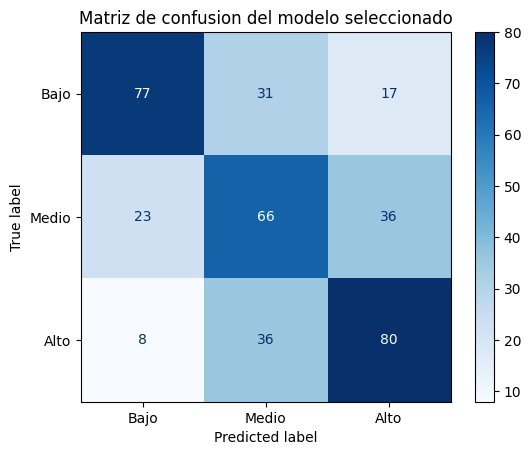


11. PREDICCION DE EJEMPLO
Nivel estimado de interaccion: Medio

RESUMEN DEL PROYECTO
Registros originales: 18409
Videos analizados: 1869
Modelos probados: 2
Modelo seleccionado: Regresion Logistica
Exactitud: 0.596
Precision macro: 0.604
Recall macro: 0.596
F1 macro: 0.598

Variables de entrada:
- Texto de los comentarios mediante TF-IDF
- Cantidad de comentarios
- Sentimiento promedio

Fin del proceso.


In [2]:

# ============================================================
# Proyecto estadísticas de Youtube Avances II
# ============================================================

# 1. IMPORTAR LAS LIBRERIAS
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from collections import Counter
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("MODELO DE PLN PARA VIDEOS DE YOUTUBE")


# 2. CARGAR EL DATASET
df = pd.read_csv("/content/comments.csv")

# Limpiar espacios en los nombres de columnas
df.columns = df.columns.str.strip()

print("Dimensiones originales:", df.shape)
print("Columnas:", df.columns.tolist())
display(df.head())


# 3. LIMPIAR Y PREPARAR LOS DATOS
# Verificar que existan las columnas necesarias
columnas = ["Video ID", "Comment", "Likes", "Sentiment"]

faltantes = [c for c in columnas if c not in df.columns]

if faltantes:
    raise ValueError(
        f"Faltan columnas necesarias en el CSV: {faltantes}"
    )

# Eliminar columnas que solo identifican el registro
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Eliminar registros sin identificador de video
df = df.dropna(subset=["Video ID"]).copy()

# Limpiar los comentarios
df["Comment"] = df["Comment"].fillna("").astype(str)
df["Comment"] = df["Comment"].str.strip()

# Convertir variables numéricas
df["Likes"] = pd.to_numeric(df["Likes"], errors="coerce")
df["Sentiment"] = pd.to_numeric(
    df["Sentiment"], errors="coerce"
)

# Los likes faltantes se reemplazan por cero
# y no se permiten valores negativos
df["Likes"] = df["Likes"].fillna(0).clip(lower=0)

# Revisar datos faltantes
print("\n2. Datos faltantes:")
print(df.isnull().sum())

print("\nCantidad de comentarios:", len(df))
print("Cantidad de videos:", df["Video ID"].nunique())


# ANALISIS ESTADISTICO DESCRIPTIVO
df["Longitud_comentario"] = df["Comment"].str.len()

print("\n3. Estadistica descriptiva:")
display(
    df[["Likes", "Longitud_comentario", "Sentiment"]]
    .describe()
)

# Distribución de los sentimientos
print("\nDistribucion de sentimientos:")
print(df["Sentiment"].value_counts(dropna=False))

df["Sentiment"].value_counts().sort_index().plot(
    kind="bar"
)
plt.title("Distribucion de sentimientos")
plt.xlabel("Codigo de sentimiento")
plt.ylabel("Cantidad de comentarios")
plt.show()

# Palabras más frecuentes
def limpiar_texto(texto):
    texto = texto.lower()
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)
    texto = re.sub(r"[^a-záéíóúüñ\s]", " ", texto)
    return texto

palabras = []

for comentario in df["Comment"]:
    palabras.extend(limpiar_texto(comentario).split())

frecuencias = Counter(palabras)

# Excluir palabras demasiado comunes en inglés y español
stopwords = {
    "the", "and", "for", "you", "this", "that", "with",
    "are", "was", "but", "have", "has", "not", "its",
    "una", "uno", "unos", "unas", "los", "las", "del",
    "por", "para", "con", "que", "como", "muy", "este",
    "esta", "esto", "pero", "sus", "más", "muy", "de",
    "la", "el", "en", "y", "a", "un", "es", "se"
}

frecuencias_filtradas = Counter({
    palabra: cantidad
    for palabra, cantidad in frecuencias.items()
    if len(palabra) > 2 and palabra not in stopwords
})

print("\n4. Palabras mas frecuentes:")
print(frecuencias_filtradas.most_common(15))

top_palabras = frecuencias_filtradas.most_common(15)

if top_palabras:
    pd.Series(dict(top_palabras)).sort_values().plot(
        kind="barh"
    )
    plt.title("Palabras mas frecuentes en los comentarios")
    plt.xlabel("Frecuencia")
    plt.show()


# AGRUPAR LOS COMENTARIOS POR VIDEO
# Cada fila representara un video
videos = df.groupby("Video ID").agg(
    Comentarios=(
        "Comment",
        lambda x: " ".join(
            comentario for comentario in x if comentario
        )
    ),
    Cantidad_comentarios=("Comment", "count"),
    Sentimiento_promedio=("Sentiment", "mean"),
    Likes_comentarios=("Likes", "sum")
).reset_index()

# Quitar videos sin comentarios utilizables
videos = videos[
    videos["Comentarios"].str.strip().ne("")
].copy()

print("\n5. Videos preparados:", len(videos))

# Revisar la relacion entre variables numericas
print("\nCorrelaciones entre variables numericas:")
display(
    videos[
        [
            "Cantidad_comentarios",
            "Sentimiento_promedio",
            "Likes_comentarios"
        ]
    ].corr()
)


# CREAR LA VARIABLE OBJETIVo, Bajo, medio y alto se definen por terciles de la suma de likes de los comentarios. Son niveles relativos a este dataset.

videos["Desempeno"] = pd.qcut(
    videos["Likes_comentarios"].rank(method="first"),
    q=3,
    labels=["Bajo", "Medio", "Alto"]
)

print("\n6. Distribucion de niveles de interaccion:")
print(videos["Desempeno"].value_counts())

videos["Desempeno"].value_counts().reindex(
    ["Bajo", "Medio", "Alto"]
).plot(kind="bar")

plt.title("Niveles de interaccion por video")
plt.xlabel("Nivel")
plt.ylabel("Cantidad de videos")
plt.xticks(rotation=0)
plt.show()


#  SELECCIONAR VARIABLES Y DIVIDIR LOS DATOS

X = videos[
    [
        "Comentarios",
        "Cantidad_comentarios",
        "Sentimiento_promedio"
    ]
]

y = videos["Desempeno"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n7. Videos para entrenar:", len(X_train))
print("Videos para probar:", len(X_test))


#  PREPROCESAMIENTO DEL TEXTO Y VARIABLES NUMERICAS
# TF-IDF convierte las palabras en numeros.

preprocesador = ColumnTransformer(
    transformers=[
        (
            "texto",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=2,
                stop_words="english",
                sublinear_tf=True
            ),
            "Comentarios"
        ),
        (
            "numericas",
            Pipeline([
                (
                    "imputar",
                    SimpleImputer(strategy="median")
                ),
                ("escalar", StandardScaler())
            ]),
            [
                "Cantidad_comentarios",
                "Sentimiento_promedio"
            ]
        )
    ]
)


#  ENTRENAR Y COMPARAR DOS MODELOS
modelos = {
    "Regresion Logistica": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Bosque Aleatorio": RandomForestClassifier(
        n_estimators=2000,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

resultados = []
modelos_entrenados = {}

print("\n8. Entrenamiento y evaluacion")

for nombre_modelo, algoritmo in modelos.items():
    pipeline = Pipeline([
        ("preprocesamiento", preprocesador),
        ("modelo", algoritmo)
    ])

    pipeline.fit(X_train, y_train)
    predicciones = pipeline.predict(X_test)

    resultados.append({
        "Modelo": nombre_modelo,
        "Exactitud": accuracy_score(
            y_test, predicciones
        ),
        "Precision_macro": precision_score(
            y_test, predicciones,
            average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_test, predicciones,
            average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_test, predicciones,
            average="macro", zero_division=0
        )
    })

    modelos_entrenados[nombre_modelo] = pipeline

# Organizar los modelos segun F1 macro
tabla = pd.DataFrame(resultados).sort_values(
    "F1_macro", ascending=False
).reset_index(drop=True)

print("\n9. Comparacion de modelos:")
display(
    tabla.style.format({
        "Exactitud": "{:.3f}",
        "Precision_macro": "{:.3f}",
        "Recall_macro": "{:.3f}",
        "F1_macro": "{:.3f}"
    })
)

mejor_nombre = tabla.loc[0, "Modelo"]
mejor_modelo = modelos_entrenados[mejor_nombre]

print("\nMODELO SELECCIONADO:", mejor_nombre)


# EVALUACION DETALLADA DEL MEJOR MODELO
y_pred = mejor_modelo.predict(X_test)

print("\n10. Reporte de clasificacion:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Bajo", "Medio", "Alto"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Bajo", "Medio", "Alto"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusion del modelo seleccionado")
plt.show()


# 11. PREDICCION DE EJEMPLO
# Datos ilustrativos: deben reemplazarse por datos reales.

nuevo_video = pd.DataFrame({
    "Comentarios": [
        "This video is very useful and informative. "
        "I learned a lot. Great explanation!"
    ],
    "Cantidad_comentarios": [25],
    "Sentimiento_promedio": [2]
})

prediccion = mejor_modelo.predict(nuevo_video)[0]

print("\n11. PREDICCION DE EJEMPLO")
print("Nivel estimado de interaccion:", prediccion)


# RESUMEN AUTOMATICO PARA EL INFORME
print("\n" + "=" * 55)
print("RESUMEN DEL PROYECTO")
print("=" * 55)

print("Registros originales:", len(df))
print("Videos analizados:", len(videos))
print("Modelos probados:", len(modelos))
print("Modelo seleccionado:", mejor_nombre)

fila_mejor = tabla.iloc[0]

print(f"Exactitud: {fila_mejor['Exactitud']:.3f}")
print(f"Precision macro: {fila_mejor['Precision_macro']:.3f}")
print(f"Recall macro: {fila_mejor['Recall_macro']:.3f}")
print(f"F1 macro: {fila_mejor['F1_macro']:.3f}")

print("\nVariables de entrada:")
print("- Texto de los comentarios mediante TF-IDF")
print("- Cantidad de comentarios")
print("- Sentimiento promedio")

print("\nFin del proceso.")


In [3]:
# para las configuraciones del modelo

# importación de la librería que permite crear copias nuevas de los modelos

from sklearn.base import clone

resultados_iteraciones = []
modelos_iterados = {}

# Diferentes configuraciones para probar
configuraciones = [
    {
        "Modelo": "Regresion Logistica",
        "Parametros": {
            "modelo__C": 0.01,
            "modelo__max_iter": 2000
        }
    },
     {
        "Modelo": "Regresion Logistica",
        "Parametros": {
            "modelo__C": 0.1,
            "modelo__max_iter": 2000
        }
    },
    {
        "Modelo": "Regresion Logistica",
        "Parametros": {
            "modelo__C": 1.0,
            "modelo__max_iter": 2000
        }
    },
    {
        "Modelo": "Regresion Logistica",
        "Parametros": {
            "modelo__C": 10.0,
            "modelo__max_iter": 2000
        }
    },

    {
        "Modelo": "Bosque Aleatorio",
        "Parametros": {
            "modelo__n_estimators": 100,
            "modelo__max_depth": 1
        }
    },
     {
        "Modelo": "Bosque Aleatorio",
        "Parametros": {
            "modelo__n_estimators": 100,
            "modelo__max_depth": 10
        }
    },
    {
        "Modelo": "Bosque Aleatorio",
        "Parametros": {
            "modelo__n_estimators": 200,
            "modelo__max_depth": 15
        }
    },
    {
        "Modelo": "Bosque Aleatorio",
        "Parametros": {
            "modelo__n_estimators": 500,
            "modelo__max_depth": 25
        }
    }
]

# Ejecutar cada configuracion
for i, config in enumerate(configuraciones, start=1):

    nombre = config["Modelo"]
    parametros = config["Parametros"]

    # Crear un modelo nuevo con la configuracion base
    algoritmo = clone(modelos[nombre])

    pipeline = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", algoritmo)
    ])

    # Cambiar los parametros de la iteracion
    pipeline.set_params(**parametros)

    # Entrenar y predecir
    pipeline.fit(X_train, y_train)
    predicciones = pipeline.predict(X_test)

    # Guardar las metricas
    metricas = {
        "Iteracion": i,
        "Modelo": nombre,
        "Configuracion": str(parametros),
        "Exactitud": accuracy_score(y_test, predicciones),
        "Precision_macro": precision_score(
            y_test, predicciones,
            average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_test, predicciones,
            average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_test, predicciones,
            average="macro", zero_division=0
        )
    }

    resultados_iteraciones.append(metricas)
    modelos_iterados[i] = pipeline

    print(f"Iteracion {i} completada: {nombre}")

# Mostrar la comparacion
tabla_iteraciones = pd.DataFrame(resultados_iteraciones)

tabla_iteraciones = tabla_iteraciones.sort_values(
    "F1_macro", ascending=False
).reset_index(drop=True)

print("\nRESULTADOS DE LAS ITERACIONES")

display(
    tabla_iteraciones.style.format({
        "Exactitud": "{:.3f}",
        "Precision_macro": "{:.3f}",
        "Recall_macro": "{:.3f}",
        "F1_macro": "{:.3f}"
    })
)

# Seleccionar la mejor configuracion por F1 macro
mejor_fila = tabla_iteraciones.iloc[0]
mejor_iteracion = int(mejor_fila["Iteracion"])
mejor_modelo = modelos_iterados[mejor_iteracion]

print("\nMEJOR ITERACION:", mejor_iteracion)
print("MODELO:", mejor_fila["Modelo"])
print("F1 MACRO:", round(mejor_fila["F1_macro"], 3))
print("Exactitud:", round(mejor_fila["Exactitud"], 3))
print("precisión macro:", round(mejor_fila["Precision_macro"], 3))
print("Recall_macro:", round(mejor_fila["Recall_macro"], 3))


Iteracion 1 completada: Regresion Logistica
Iteracion 2 completada: Regresion Logistica
Iteracion 3 completada: Regresion Logistica
Iteracion 4 completada: Regresion Logistica
Iteracion 5 completada: Bosque Aleatorio
Iteracion 6 completada: Bosque Aleatorio
Iteracion 7 completada: Bosque Aleatorio
Iteracion 8 completada: Bosque Aleatorio

RESULTADOS DE LAS ITERACIONES


,Iteracion,Modelo,Configuracion,Exactitud,Precision_macro,Recall_macro,F1_macro
0,2,Regresion Logistica,"{'modelo__C': 0.1, 'modelo__max_iter': 2000}",0.599,0.636,0.599,0.603
1,3,Regresion Logistica,"{'modelo__C': 1.0, 'modelo__max_iter': 2000}",0.596,0.604,0.596,0.598
2,4,Regresion Logistica,"{'modelo__C': 10.0, 'modelo__max_iter': 2000}",0.586,0.591,0.586,0.588
3,8,Bosque Aleatorio,"{'modelo__n_estimators': 500, 'modelo__max_depth': 25}",0.572,0.575,0.572,0.572
4,7,Bosque Aleatorio,"{'modelo__n_estimators': 200, 'modelo__max_depth': 15}",0.543,0.542,0.543,0.541
5,6,Bosque Aleatorio,"{'modelo__n_estimators': 100, 'modelo__max_depth': 10}",0.537,0.535,0.538,0.535
6,5,Bosque Aleatorio,"{'modelo__n_estimators': 100, 'modelo__max_depth': 1}",0.527,0.518,0.527,0.514
7,1,Regresion Logistica,"{'modelo__C': 0.01, 'modelo__max_iter': 2000}",0.430,0.525,0.431,0.426



MEJOR ITERACION: 2
MODELO: Regresion Logistica
F1 MACRO: 0.603
Exactitud: 0.599
precisión macro: 0.636
Recall_macro: 0.599
